In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, roc_auc_score,
)
 
from imblearn.over_sampling import SMOTENC
 
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', "{:.3f}".format)

In [2]:
df = pd.read_csv("penguins.csv")
print("shape of the dataset",df.shape)
print("Columns:",df.columns.tolist())
df.head()

shape of the dataset (344, 7)
Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.100,18.700,181.000,3750.000,MALE
1,Adelie,Torgersen,39.500,17.400,186.000,3800.000,FEMALE
2,Adelie,Torgersen,40.300,18.000,195.000,3250.000,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.700,19.300,193.000,3450.000,FEMALE


In [10]:
target_col = "species"
num_cols = ["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]
cat_cols = ["island","sex"]
#MALE,FEMALE -> Male/Female
df["sex"] = df["sex"].str.title()
df["sex"] = df["sex"].where(df["sex"].isin(["Male","Female"]))
#########
before = len(df)
df=df.dropna(subset=num_cols, how="all").reset_index(drop = True)
print(df.shape)
print(df.head())

(342, 7)
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen          39.100         18.700            181.000   
1  Adelie  Torgersen          39.500         17.400            186.000   
2  Adelie  Torgersen          40.300         18.000            195.000   
3  Adelie  Torgersen          36.700         19.300            193.000   
4  Adelie  Torgersen          39.300         20.600            190.000   

   body_mass_g     sex  
0     3750.000    Male  
1     3800.000  Female  
2     3250.000  Female  
3     3450.000  Female  
4     3650.000    Male  


In [11]:
print("Target distribution:")
print(df[target_col].value_counts())
print(df[target_col].value_counts(normalize=True))
print("-" * 40)
print("Missing values per column:")
print(df.isnull().sum())

Target distribution:
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64
species
Adelie      0.442
Gentoo      0.360
Chinstrap   0.199
Name: proportion, dtype: float64
----------------------------------------
Missing values per column:
species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64


In [12]:
pd.crosstab(df["island"],df[target_col])

species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,123
Dream,56,68,0
Torgersen,51,0,0


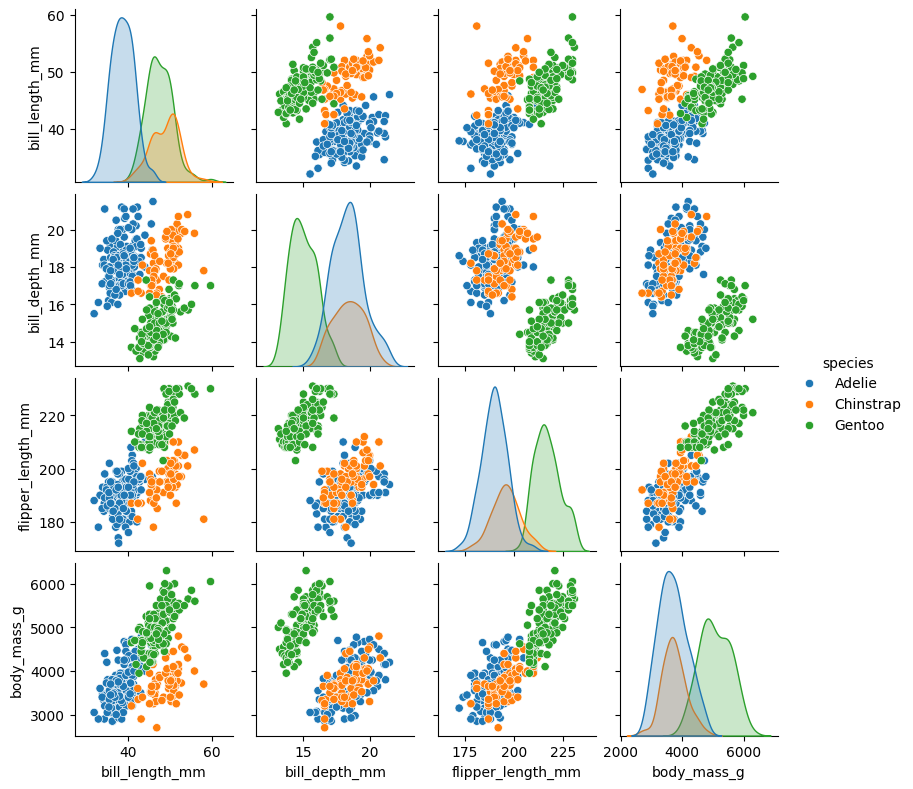

In [14]:
sns.pairplot(df,hue=target_col,vars=num_cols,height=2)
plt.show()

In [16]:
target_encoder = LabelEncoder()
y_all = target_encoder.fit_transform(df[target_col])
class_names = target_encoder.classes_

for i,name in enumerate(class_names):
    print(i, "->", name)

0 -> Adelie
1 -> Chinstrap
2 -> Gentoo


In [17]:
X = df.drop(columns=[target_col])
y = pd.Series(y_all, name=target_col)
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # keeps all 3 class ratios the same in train and test
)
 
print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
 
X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

Train shape: (273, 6)
Test shape : (69, 6)


In [18]:
num_imputer = SimpleImputer(strategy="median")
X_train_processed[num_cols] = num_imputer.fit_transform(X_train_processed[num_cols])
X_test_processed[num_cols] = num_imputer.transform(X_test_processed[num_cols])
 
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train_processed[cat_cols] = cat_imputer.fit_transform(X_train_processed[cat_cols])
X_test_processed[cat_cols] = cat_imputer.transform(X_test_processed[cat_cols])
 
print("Missing values left (train):", X_train_processed.isnull().sum().sum())
print("Missing values left (test) :", X_test_processed.isnull().sum().sum())

Missing values left (train): 0
Missing values left (test) : 0


In [19]:
#to handle the outliers check and plot

In [20]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr
 
for col in num_cols:
    low, high = iqr_bounds(X_train_processed[col])
    n_out = ((X_train_processed[col] < low) | (X_train_processed[col] > high)).sum()
    print(f"{col:20s} outliers: {n_out}")
 

bill_length_mm       outliers: 0
bill_depth_mm        outliers: 0
flipper_length_mm    outliers: 0
body_mass_g          outliers: 0


In [22]:
for d in(X_train_processed,X_test_processed):
    d["bill_ratio"] = d["bill_length_mm"] / d["bill_depth_mm"]
num_cols_final = num_cols + ["bill_ratio"]
print(num_cols_final)

['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'bill_ratio']


In [23]:
for d in (X_train_processed, X_test_processed):
    d["sex"] = d["sex"].map({"Male": 1, "Female": 0})
 
assert X_train_processed["sex"].isnull().sum() == 0
assert X_test_processed["sex"].isnull().sum() == 0

In [26]:
scaler = StandardScaler()
X_train_processed[num_cols_final] = scaler.fit_transform(X_train_processed[num_cols_final])
X_test_processed[num_cols_final]  = scaler.transform(X_test_processed[num_cols_final])
X_train_processed.head()

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,bill_ratio
110,Biscoe,0.279,1.579,-0.717,0.489,1,-0.737
27,Biscoe,-1.125,0.731,-2.085,-1.327,0,-1.151
17,Torgersen,-1.763,0.631,-1.221,-1.108,0,-1.484
283,Biscoe,0.315,-1.464,1.300,0.614,0,1.202
210,Dream,0.279,1.130,-0.501,-0.857,0,-0.531


In [27]:
print("Before SMOTENC:")
print(pd.Series(target_encoder.inverse_transform(y_train)).value_counts())
 
smote = SMOTENC(categorical_features=["island", "sex"], random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_processed, y_train)
 
print("-" * 40)
print("After SMOTENC:")
print(pd.Series(target_encoder.inverse_transform(y_train_res)).value_counts())

Before SMOTENC:
Adelie       121
Gentoo        98
Chinstrap     54
Name: count, dtype: int64
----------------------------------------
After SMOTENC:
Adelie       121
Gentoo       121
Chinstrap    121
Name: count, dtype: int64
